In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
returns_df = pd.read_parquet(PROCESSED_DIR / "daily_returns.parquet")
adj_close_df = pd.read_parquet(PROCESSED_DIR / "adjusted_close.parquet")

tickers = returns_df.columns.tolist()

raw_data = {
    ticker: pd.read_parquet(RAW_DIR / f"{ticker}.parquet")
    for ticker in tickers
}
daily_returns = pd.DataFrame({
    ticker: raw_data[ticker]["Adj Close"].pct_change()
    for ticker in tickers
}).sort_index()

print("Tickers loaded:", tickers)
print("raw_data count:", len(raw_data))
print("Common returns_df shape:", returns_df.shape)

Tickers loaded: ['SPY', 'QQQ', 'IWM', 'EWJ', 'VGK', 'TLT', 'IEF', 'SHY', 'GLD', 'SLV', 'DBC', 'USO', 'UUP', 'FXE', 'FXY']
raw_data count: 15
Common returns_df shape: (4959, 15)


In [5]:
# 17.full adjusted-close panel

adj_close_full = pd.DataFrame({
    ticker: raw_data[ticker]["Adj Close"]
    for ticker in tickers
})

adj_close_full = adj_close_full.sort_index()

print("Shape:", adj_close_full.shape)
print("Start:", adj_close_full.index.min())
print("End:", adj_close_full.index.max())

Shape: (6758, 15)
Start: 2000-01-03 00:00:00
End: 2026-11-13 00:00:00


In [7]:
# 18. 12-month momentum

LOOKBACK = 252
momentum_252 = (
    adj_close_full / adj_close_full.shift(LOOKBACK)
) - 1

display(momentum_252.loc["2008-03":"2008-06"].tail())

,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2008-06-24,-0.106760,-0.002919,-0.134894,-0.114940,-0.098562,0.127247,0.124888,0.068812,0.357597,0.285926,0.732012,1.135296,-0.083104,0.195949,0.143316
2008-06-25,-0.093219,0.019113,-0.118587,-0.102749,-0.085231,0.127478,0.124482,0.070258,0.374096,0.368958,0.745378,1.122457,-0.086075,0.205029,0.140586
2008-06-26,-0.130223,-0.036833,-0.158837,-0.127179,-0.112906,0.133989,0.130954,0.073503,0.423119,0.394349,0.806075,1.180416,-0.093175,0.212932,0.147095
2008-06-27,-0.134857,-0.036427,-0.157880,-0.120411,-0.113847,0.147558,0.137215,0.074290,0.423436,0.397581,0.816475,1.167905,-0.095995,0.214173,0.156677
2008-06-30,-0.132092,-0.048161,-0.160862,-0.127499,-0.113144,0.136082,0.132098,0.072794,0.422126,0.397814,0.785589,1.144528,-0.088519,0.202982,0.155835


In [8]:
# 19.extract month-end momentum observations

month_end_momentum = (
    momentum_252
    .groupby(momentum_252.index.to_period("M"))
    .tail(1)
)

print("Monthly observations:", len(month_end_momentum))

display(month_end_momentum.tail())

Monthly observations: 323


,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2026-07-31,0.190473,0.217041,0.327968,0.302618,0.220527,-0.010036,0.018594,0.030372,0.234516,0.562519,0.344575,0.593904,0.046411,0.017440,-0.063961
2026-08-31,0.195138,0.248028,0.257230,0.261293,0.198138,-0.010569,0.001568,0.023933,0.296448,0.692849,0.458676,0.776980,0.061715,0.002345,-0.083959
2026-09-30,0.161490,0.241371,0.161797,0.262650,0.129297,-0.092451,-0.037870,0.015051,0.080520,0.282588,0.476913,0.952809,0.080340,-0.026513,-0.059128
2026-10-30,0.111266,0.091172,0.143121,0.164365,0.113206,-0.059873,-0.015681,0.020934,-0.019890,0.031691,0.529775,1.351393,0.070322,-0.029194,-0.033389
2026-11-13,0.115790,0.099833,0.150713,0.134818,0.115353,-0.077769,-0.033190,0.015352,-0.079121,-0.086714,0.381348,1.085972,0.083748,-0.040876,-0.034169


In [9]:
# 20.binary momentum signals

#1.0 = long
#-1.0 = short
#0.0 = neutral

month_end_signals = np.sign(month_end_momentum)

month_end_signals = month_end_signals.astype(float)

display(month_end_signals.tail(12))

,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2025-12-31,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,-1.0,1.0,1.0
2026-01-30,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2026-02-27,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,-1.0
2026-03-31,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0
2026-04-30,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0
2026-05-29,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0
2026-06-30,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,-1.0
2026-07-31,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0
2026-08-31,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0


In [10]:
# 21.convert monthly signals into daily positions

SIGNAL_DELAY = 2

daily_positions = (
    month_end_signals
    .reindex(adj_close_full.index)
    .ffill()
    .shift(SIGNAL_DELAY)
)

display(daily_positions.loc["2008-03":"2008-06"])

,SPY,QQQ,IWM,EWJ,VGK,TLT,IEF,SHY,GLD,SLV,DBC,USO,UUP,FXE,FXY
Date,,,,,,,,,,,,,,,
2008-03-03,-1.0,1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,NaN
2008-03-04,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2008-03-05,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2008-03-06,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2008-03-07,-1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008-06-24,-1.0,1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2008-06-25,-1.0,1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0
2008-06-26,-1.0,1.0,-1.0,-1.0,-1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,-1.0,1.0,1.0


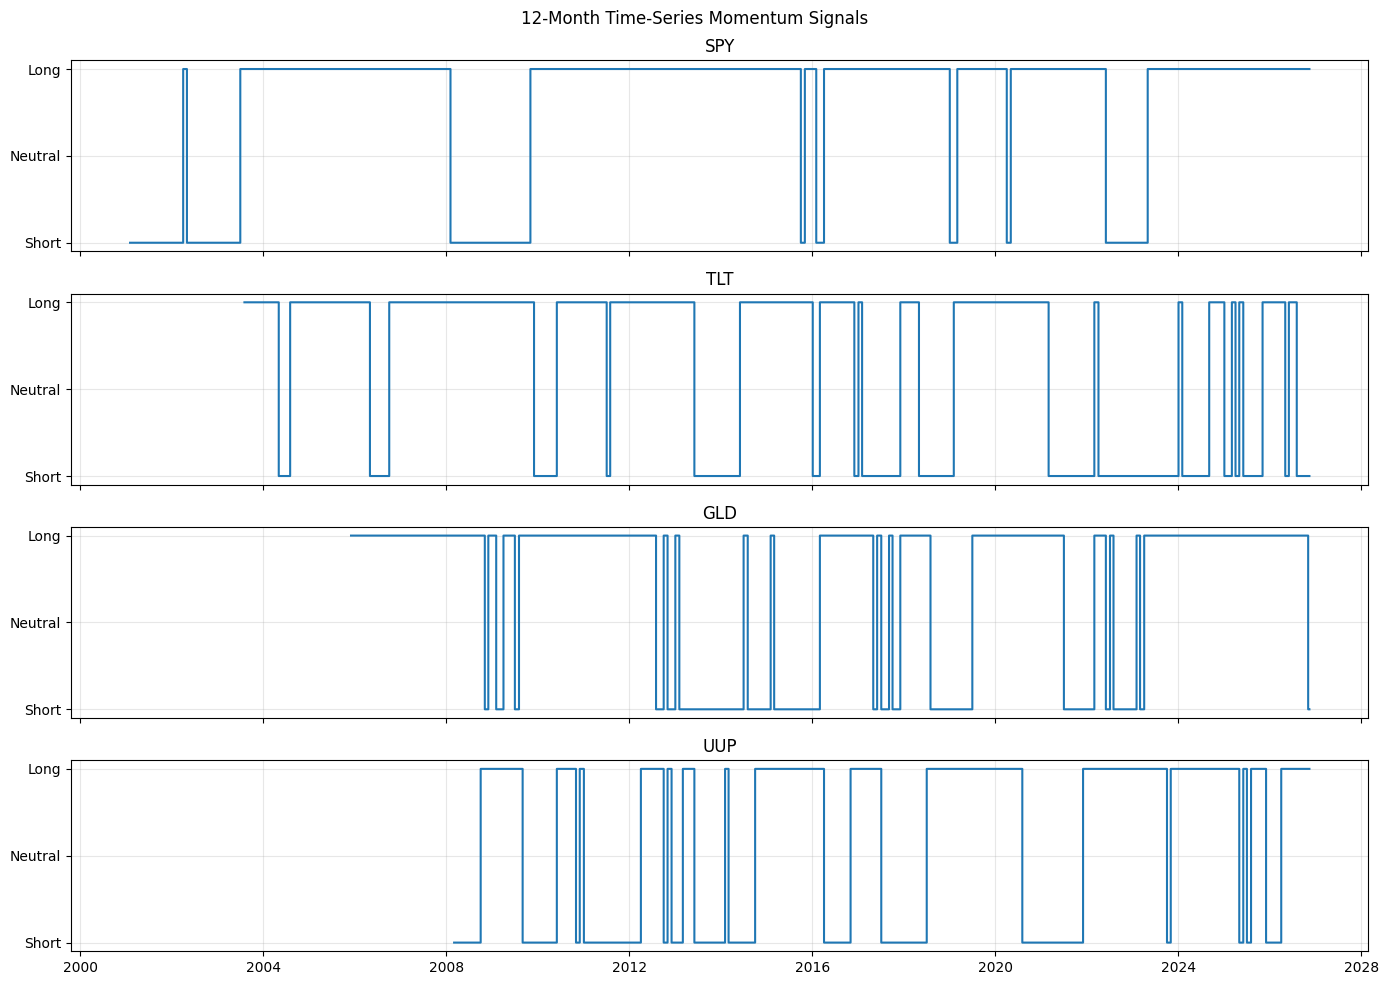

In [11]:
# 22.momentum signals plot

selected_tickers = ["SPY", "TLT", "GLD", "UUP"]

fig, axes = plt.subplots(
    len(selected_tickers),
    1,
    figsize=(14, 10),
    sharex=True
)

for ax, ticker in zip(axes, selected_tickers):

    ax.step(
        daily_positions.index,
        daily_positions[ticker],
        where="post"
    )

    ax.set_title(ticker)
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(["Short", "Neutral", "Long"])
    ax.grid(alpha=0.3)

plt.suptitle("12-Month Time-Series Momentum Signals")
plt.tight_layout()
plt.show()

In [12]:
# 23.signal distribution

signal_counts = pd.DataFrame({
    "Long": (month_end_signals == 1).sum(),
    "Short": (month_end_signals == -1).sum(),
    "Neutral": (month_end_signals == 0).sum(),
    "Unavailable": month_end_signals.isna().sum()
})

display(signal_counts)

,Long,Short,Neutral,Unavailable
SPY,245,66,0,12
QQQ,249,62,0,12
IWM,216,91,0,16
EWJ,195,116,0,12
VGK,168,81,0,74
TLT,178,103,0,42
IEF,198,83,0,42
SHY,245,36,0,42
GLD,176,77,0,70
SLV,132,103,0,88


In [13]:
# 24.signal proportions

valid_signals = month_end_signals.notna().sum()

signal_proportions = pd.DataFrame({
    "Long (%)": (month_end_signals == 1).sum() / valid_signals * 100,
    "Short (%)": (month_end_signals == -1).sum() / valid_signals * 100,
    "Neutral (%)": (month_end_signals == 0).sum() / valid_signals * 100
})

display(signal_proportions.round(2))

,Long (%),Short (%),Neutral (%)
SPY,78.78,21.22,0.0
QQQ,80.06,19.94,0.0
IWM,70.36,29.64,0.0
EWJ,62.70,37.30,0.0
VGK,67.47,32.53,0.0
TLT,63.35,36.65,0.0
IEF,70.46,29.54,0.0
SHY,87.19,12.81,0.0
GLD,69.57,30.43,0.0
SLV,56.17,43.83,0.0


In [15]:
# Save momentum signals and daily positions to data/processed
month_end_signals.to_parquet(PROCESSED_DIR / "month_end_signals.parquet")
daily_positions.to_parquet(PROCESSED_DIR / "daily_positions.parquet")

print("Momentum signal files saved successfully:")
print(" - month_end_signals.parquet:", month_end_signals.shape)
print(" - daily_positions.parquet:", daily_positions.shape)

Momentum signal files saved successfully:
 - month_end_signals.parquet: (323, 15)
 - daily_positions.parquet: (6758, 15)


In [16]:
# Final cell of 03_momentum_signals.ipynb: Save signals to data/processed
month_end_signals.to_parquet(PROCESSED_DIR / "month_end_signals.parquet")
daily_positions.to_parquet(PROCESSED_DIR / "daily_positions_full.parquet")

# Align daily positions to the common sample (4959, 15) used in 04_volatility_estimation
daily_positions_common = daily_positions.reindex(returns_df.index)
daily_positions_common.to_parquet(PROCESSED_DIR / "daily_positions.parquet")

print("Saved momentum files:")
print(" - month_end_signals.parquet:", month_end_signals.shape)
print(" - daily_positions_full.parquet:", daily_positions.shape)
print(" - daily_positions.parquet (common sample):", daily_positions_common.shape)
print("Missing values in common sample positions:", daily_positions_common.isna().sum().sum())

Saved momentum files:
 - month_end_signals.parquet: (323, 15)
 - daily_positions_full.parquet: (6758, 15)
 - daily_positions.parquet (common sample): (4959, 15)
Missing values in common sample positions: 612
